# SafeViChi v2 · Hier-BidirLM-0.6B GuardMerge
**Mục tiêu** là tinh chỉnh một mô hình trả về một trong năm nhãn ưu tiên cùng các cụm từ chép nguyên văn. Mỗi lượt thoại được mã hóa hai chiều. Lớp attention thứ hai kết hợp các lượt theo thứ tự. Đầu phân loại có một truy vấn riêng cho mỗi nhãn. Đầu bằng chứng nhận cả biểu diễn token lẫn ngữ cảnh của lượt.

**Môi trường** dùng Python 3.11 trở lên, PyTorch/CUDA do Colab cung cấp và các gói đã ghim trong ô `%pip`. Nếu kernel đã nạp một phiên bản cũ, chạy ô cài đặt rồi chọn *Restart session* trước khi chạy các ô Python. [Runtime Colab](https://research.google.com/colaboratory/runtime-version-faq.html) · [IPython %pip](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-pip)

**Chạy trên Colab** bằng cách chọn GPU (T4 16 GB trở lên nên dùng), chạy ô cài gói, sau đó chọn *Runtime → Restart session* nếu được yêu cầu. Trước tiên chạy ở `RUN_MODE = "smoke"` để kiểm tra đường dẫn, mô hình, loss và checkpoint; khi thử nghiệm hoàn tất, đổi sang `RUN_MODE = "full"` và chạy lại từ ô cấu hình. Mặc định tải bộ dữ liệu công khai ở commit cố định và lưu sau từng epoch vào Google Drive (Colab sẽ hỏi quyền gắn Drive). Có thể đổi thư mục đầu ra hoặc dùng ổ tạm. Khi phiên bị ngắt, chạy lại cùng cấu hình để tiếp tục từ cuối epoch gần nhất. Mặc định là `RUN_MODE = "smoke"`, không phải huấn luyện đầy đủ. Bản đầy đủ dùng LoRA trên nền đã trộn, bộ nhớ huấn luyện lớn hơn ngân sách triển khai 2 GB.

**Phạm vi.** Dữ liệu chỉ có nhãn ưu tiên, bằng chứng và văn bản 1–8 lượt. Phần ORC về chủ đề, điểm nghiêm trọng, W-ASL đa nhãn và chưng cất lời giải thích cần nhãn bổ sung. Lần chạy này dùng cross-entropy cho năm lớp và BCE có mặt nạ cho bằng chứng. Điểm tin cậy sau hiệu chuẩn là xác suất của lớp. Bộ nhớ, độ trễ và chất lượng phải đo trên thiết bị và dữ liệu mục tiêu.

[Nghiên cứu BidirLM, mục 6.1](https://arxiv.org/html/2604.02045#S6.SS1) · [Checkpoint BidirLM](https://huggingface.co/BidirLM/BidirLM-0.6B-Base) · [Checkpoint Qwen3Guard](https://huggingface.co/Qwen/Qwen3Guard-Gen-0.6B)

**Lưu ý khi chạy:** Khoảng 2,4 GB trọng số gốc được tải xuống ổ tạm của Colab, cần thêm RAM/VRAM cho nạp và huấn luyện. Chạy toàn bộ có thể vượt giới hạn thời gian phiên GPU miễn phí; đừng dùng kết quả smoke để kết luận về độ chính xác. Theo mặc định chỉ báo cáo trên dev, không sử dụng audit để dò cấu hình.

In [ ]:
%pip -q install "transformers==4.57.6" "tokenizers==0.22.2" "safetensors==0.6.2" "huggingface-hub==0.36.0" "scikit-learn==1.9.1"

## Kiểm tra GPU và dung lượng Colab trước khi tải mô hình
Nếu ô này dừng vì thiếu GPU, chọn **Runtime → Change runtime type → GPU** rồi chạy lại. Mô hình sử dụng hai tệp trọng số lớn và các biến trung gian, do đó chỉ nên chạy thử trên GPU. Dung lượng lưu trữ hiển thị là dung lượng ổ tạm, không phải Drive.

In [ ]:
from pathlib import Path
import shutil
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Chưa có GPU CUDA. Chọn Runtime → Change runtime type → GPU, sau đó chạy lại.")

gpu_name = torch.cuda.get_device_name(0)
gpu_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
free_gib = shutil.disk_usage("/content" if Path("/content").exists() else ".").free / 2**30
print(f"GPU: {gpu_name} | VRAM: {gpu_gib:.1f} GiB | Ổ tạm còn trống: {free_gib:.1f} GiB")
if free_gib < 5.0:
    raise RuntimeError("Ổ tạm còn dưới 5 GiB. Xóa bớt tệp trước khi tải trọng số.")
if gpu_gib < 12.0:
    print("CẢNH BÁO: VRAM dưới 12 GiB. Có thể cần giảm BATCH hoặc CHUNK để tránh CUDA OOM.")

GPU: Tesla T4 | VRAM: 14.6 GiB | Ổ tạm còn trống: 109.7 GiB


In [ ]:
import os, sys, json, hashlib, random, math, time, platform, unicodedata, re
from pathlib import Path
from collections import Counter, defaultdict
from contextlib import nullcontext
from itertools import islice
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, log_loss
from scipy.optimize import minimize_scalar
from scipy.special import softmax
from huggingface_hub import hf_hub_download
from safetensors import safe_open
from safetensors.torch import save_file, load_file
from tokenizers import Tokenizer
from transformers import Qwen3Config, Qwen3Model
import transformers, requests, sklearn, scipy, tokenizers, huggingface_hub, safetensors

RUN_MODE = "full"      # smoke = kiểm thử một epoch; đổi thành "full" để huấn luyện thật
USE_DRIVE = True
MERGE_RATIO = 0.5       # 0.0 = baseline BidirLM
TURN_MODE = "hier"      # "flat" để đo đóng góp của phân cấp
SPAN_WEIGHT = 0.35      # 0.0 để đo đóng góp của học bằng chứng
EVIDENCE_POOL = True   # dùng bằng chứng làm tín hiệu phụ cho phân loại
PROTOTYPE_WEIGHT = 0.0 # thử 0.1 trên dev với nguyên mẫu đơn nhãn
ACCENT_AUG = 0.0       # thử 0.1 để thêm bản bỏ dấu vào fit mỗi epoch
SEED = 42
EPOCHS = 3 if RUN_MODE == "full" else 1
BATCH, ACCUM = 2, 8     # số hội thoại mỗi batch, số bước tích lũy
CHUNK, WIDTH, RANK = 192, 192, 16
LR_ADAPTER, LR_HEAD = 1e-4, 4e-4
RUN_INT8_CPU = False   # benchmark tùy chọn, cần thêm RAM CPU
assert 0 <= ACCENT_AUG <= 1 and PROTOTYPE_WEIGHT >= 0 and SPAN_WEIGHT >= 0
assert RUN_MODE in {"full","smoke"} and TURN_MODE in {"hier","flat"} and 0 <= MERGE_RATIO <= 1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Notebook cần GPU. Chọn Runtime → Change runtime type → GPU rồi chạy lại.")
native_bf16 = DEVICE.type=="cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
DTYPE = (torch.bfloat16 if native_bf16 else torch.float16) if DEVICE.type=="cuda" else torch.float32
assert BATCH >= 1 and ACCUM >= 1
pinned = {"transformers": (transformers.__version__, "4.57.6"), "tokenizers": (tokenizers.__version__, "0.22.2"),
          "huggingface-hub": (huggingface_hub.__version__, "0.36.0"), "safetensors": (safetensors.__version__, "0.6.2"),
          "scikit-learn": (sklearn.__version__, "1.9.1")}
for package, (active, expected) in pinned.items():
    if active != expected:
        raise RuntimeError(f"{package} đang dùng {active}, cần {expected}. Chạy ô cài đặt, khởi động lại kernel rồi Run all.")
def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all(SEED)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/SafeViChi/guardmerge") if USE_DRIVE else Path.cwd() / "guardmerge_runs"
DATA_REV = "a1f08990c24952a004ed5b8702f852c89e484e4e"
BASE, BREV = "BidirLM/BidirLM-0.6B-Base", "a6c88fa4f7653ad82237ba00d85b1e68b8255316"
GUARD, GREV = "Qwen/Qwen3Guard-Gen-0.6B", "fada3b2f655b89601929198343c94cd2f64d93cc"
LABELS = ["AN_TOAN","XUC_PHAM","QUAY_ROI","DE_DOA","LUA_DAO"]
config = dict(schema=3, evidence_pool=EVIDENCE_POOL, prototype=PROTOTYPE_WEIGHT, accent_aug=ACCENT_AUG, dataset=DATA_REV, base=BASE, base_rev=BREV, guard=GUARD, guard_rev=GREV,
              ratio=MERGE_RATIO, mode=RUN_MODE, turns=TURN_MODE, span_weight=SPAN_WEIGHT, seed=SEED, split_seed=42,
              epochs=EPOCHS, batch=BATCH, accum=ACCUM, chunk=CHUNK, width=WIDTH, rank=RANK,
              lr_adapter=LR_ADAPTER, lr_head=LR_HEAD, labels=LABELS, dtype=str(DTYPE))
def digest(b): return hashlib.sha256(b).hexdigest()
RUN = ROOT / digest(json.dumps(config, sort_keys=True).encode())[:14]
RUN.mkdir(parents=True, exist_ok=True)
def write_json(path, obj):
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False), encoding="utf8")
    os.replace(tmp,path)
write_json(RUN/"config.json",config)
environment = dict(python=sys.version, torch=str(torch.__version__), cuda=torch.version.cuda,
                   device=torch.cuda.get_device_name() if DEVICE.type=="cuda" else platform.processor(),
                   capability=torch.cuda.get_device_capability() if DEVICE.type=="cuda" else None,
                   native_bf16=native_bf16, dtype=str(DTYPE), fp16_scaler=DTYPE==torch.float16,
                   numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__, requests=requests.__version__,
                   **{name: active for name,(active,_) in pinned.items()})
write_json(RUN/"environment.json",environment)
print(RUN, environment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/SafeViChi/guardmerge/56ee7683db5516 {'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'torch': '2.14.1+cu130', 'cuda': '13.0', 'device': 'Tesla T4', 'capability': (7, 5), 'native_bf16': False, 'dtype': 'torch.float16', 'fp16_scaler': True, 'numpy': '2.4.6', 'scipy': '1.16.3', 'pandas': '2.2.3', 'requests': '2.32.4', 'transformers': '4.57.6', 'tokenizers': '0.22.2', 'huggingface-hub': '0.36.0', 'safetensors': '0.6.2', 'scikit-learn': '1.9.1'}


## Kiểm tra dữ liệu và chia tập
Đọc đúng 13.392 bản ghi, đối chiếu SHA-256, nhãn, nguồn và cụm bằng chứng. Metadata chỉ phục vụ chia tập và phân tích. Mỗi nhóm prompt sinh và phiên bản an toàn cùng nhóm vào một fold. Tập tạm nội bộ có tỷ lệ xấp xỉ 70% để học, 10% chọn checkpoint, 10% hiệu chuẩn và 10% đánh giá cuối. Kho test dành cho người gán được giữ riêng. Các điểm ở đây đo khả năng khớp nhãn LLM trên nguồn hiện có.

In [ ]:
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

DATA_HTTP = requests.Session()
DATA_HTTP.mount("https://", HTTPAdapter(max_retries=Retry(total=3, connect=3, read=3,
    backoff_factor=1, status_forcelist=(429, 500, 502, 503, 504))))
DATA_URL = f"https://raw.githubusercontent.com/thaoanhlehoang/SafeViChi/{DATA_REV}/data/v2/"
def fetch_data(name, expected):
    cache = Path.cwd() / ".safevichi_data" / DATA_REV
    cache.mkdir(parents=True, exist_ok=True)
    path = cache/name
    if not path.exists() or digest(path.read_bytes()) != expected:
        res = DATA_HTTP.get(DATA_URL+name, timeout=(15, 180))
        res.raise_for_status()
        assert digest(res.content)==expected, f"Checksum sai: {name}"
        path.write_bytes(res.content)
    return [json.loads(line) for line in path.read_text(encoding="utf8").splitlines()]
rows = fetch_data("so_sanh.jsonl","c2c5046fcd2e3853e76ecc79c7ea70eaad79743380e03185bc32610ebc813102")
train_rows = fetch_data("train.jsonl","4a31dcee5b93392f1b5d6fba778d9121604aa59beaa8252b3026ce1112ca334f")
assert len(rows)==len(train_rows)==13392
assert len({r["id"] for r in rows})==len({r["nhom_trung"] for r in rows})==len(rows)
for r,t in zip(rows,train_rows):
    assert t=={k:r[k] for k in ("id","text","nhan","bang_chung")}
    assert r["nhan"] in LABELS and r["bien_dang"]=="C0"
    assert r["so_dong"]==len(r["text"].splitlines()) and 1<=r["so_dong"]<=8
    assert all(any(p in line for line in r["text"].splitlines()) for p in r["bang_chung"])
del train_rows
def split_group(r):
    if r["meta"]["loai"]=="sinh":
        return "prompt/"+r["nguon_id"].rsplit(":",1)[0].removesuffix("-SD")
    return "real/"+str(r["nhom_trung"])
groups = np.array([split_group(r) for r in rows])
strata = [r["nhan"]+"/"+r["meta"]["loai"] for r in rows]
fold = np.full(len(rows),-1)
for i,(_,ix) in enumerate(StratifiedGroupKFold(10,shuffle=True,random_state=config["split_seed"]).split(groups,strata,groups)):
    fold[ix]=i
parts = {k:[rows[i] for i in np.flatnonzero(mask)] for k,mask in
         {"fit":fold>=3,"dev":fold==2,"cal":fold==1,"audit":fold==0}.items()}
assert len(set.union(*(set(map(split_group,v)) for v in parts.values())))==sum(len(set(map(split_group,v))) for v in parts.values())
if RUN_MODE=="smoke":
    for k,v in parts.items():
        per_label=8 if k=="fit" else 2
        parts[k]=[r for label in LABELS for r in [x for x in v if x["nhan"]==label][:per_label]]
for v in parts.values(): assert set(r["nhan"] for r in v)==set(LABELS)
write_json(RUN/"split_ids.json",{k:[r["id"] for r in v] for k,v in parts.items()})
print(pd.DataFrame({k:Counter(r["nhan"] for r in v) for k,v in parts.items()}))
print(pd.crosstab([r["nhan"] for r in rows],[r["meta"]["loai"] for r in rows]))

           fit  dev  cal  audit
AN_TOAN   4178  596  597    596
XUC_PHAM  2095  301  300    301
DE_DOA    1063  151  151    152
LUA_DAO   1225  176  174    176
QUAY_ROI   812  116  117    115
col_0     sinh  that
row_0               
AN_TOAN   2000  3967
DE_DOA    1361   156
LUA_DAO   1751     0
QUAY_ROI  1098    62
XUC_PHAM   470  2527


## Token hóa và mục tiêu bằng chứng
Giữ nguyên chuỗi và vị trí ký tự để trả bằng chứng về văn bản gốc. Mỗi lượt dài được chia thành các khối liên tiếp để giữ cả đuôi. Mẫu nguy hại thiếu bằng chứng vẫn đóng góp vào phân loại. Với cụm lặp ở nhiều vị trí, bỏ qua các vị trí mơ hồ khi tính loss. Từ ngắt bằng khoảng trắng là đơn vị chấm bằng chứng. Cách này cần được dùng nhất quán khi so với mô hình khác.

In [ ]:
def hub(repo, name, rev):
    return hf_hub_download(repo, name, revision=rev)
tok_path = hub(BASE,"tokenizer.json",BREV)
tok = Tokenizer.from_file(tok_path)
tok.no_truncation()
tok.no_padding()
BOS, PAD = 151644,151645

def strip_accents(text):
    return "".join(c for c in unicodedata.normalize("NFD",text) if unicodedata.category(c)!="Mn").translate(
        str.maketrans({"đ":"d","Đ":"D"}))

def annotations(row):
    text = row["text"]
    yes,unknown = [],[]
    for phrase in set(row["bang_chung"]):
        positions=[m.start() for m in re.finditer("(?="+re.escape(phrase)+")",text)]
        target=yes if len(positions)==1 else unknown
        target.extend((s,s+len(phrase)) for s in positions)
    return yes,unknown

def overlaps(interval, spans):
    a,b=interval
    return any(a<end and start<b for start,end in spans)

def prepare(row):
    text=row["text"]
    yes,unknown=annotations(row)
    skip=row["nhan"]!="AN_TOAN" and not yes and not unknown
    lines=[text] if TURN_MODE=="flat" else text.split("\n")
    chunks=[]
    cursor=0
    for turn,line in enumerate(lines):
        seq=tok.encode(line,add_special_tokens=False)
        offsets=[]
        for a,b in seq.offsets:
            # NFC của tokenizer có thể bỏ dấu tổ hợp ở cuối offset gốc.
            while a<b and b<len(line) and unicodedata.combining(line[b]):
                b+=1
            offsets.append((cursor+a,cursor+b))
        for start in range(0,len(seq.ids),CHUNK):
            off=offsets[start:start+CHUNK]
            targets=[-100 if skip or a==b or overlaps((a,b),unknown) else int(overlaps((a,b),yes))
                     for a,b in off]
            chunks.append((turn,seq.ids[start:start+CHUNK],off,targets))
        cursor+=len(line)+1
    if not chunks: raise ValueError(f"Văn bản rỗng {row['id']}")
    return dict(row=row,chunks=chunks,label=LABELS.index(row["nhan"]))

def collate(examples):
    chunks=[(i,*chunk) for i,e in enumerate(examples) for chunk in e["chunks"]]
    n=max(len(ids) for _,_,ids,_,_ in chunks)+1
    tokens=torch.full((len(chunks),n),PAD,dtype=torch.long)
    mask=torch.zeros_like(tokens,dtype=torch.bool)
    targets=torch.full_like(tokens,-100)
    owners, turns, offsets=[],[],[]
    for j,(i,t,ids,off,labels) in enumerate(chunks):
        end=len(ids)+1
        tokens[j,:end]=torch.tensor([BOS]+ids)
        mask[j,:end]=True
        targets[j,1:end]=torch.tensor(labels)
        owners.append(i)
        turns.append(t)
        offsets.append(off)
    return dict(ids=tokens,mask=mask,targets=targets,owner=torch.tensor(owners),
                turn=torch.tensor(turns),offsets=offsets,examples=examples,
                labels=torch.tensor([e["label"] for e in examples]))
# Đối chiếu offset trên chuỗi gốc, kể cả dấu tổ hợp và trường hợp một từ sinh nhiều token.
for form in ("NFC","NFD","bo_dau"):
    needle=unicodedata.normalize("NFD" if form=="NFD" else "NFC","dữ")
    if form=="bo_dau": needle=strip_accents(needle)
    sample="Chào bạn!\n"+needle+" thoại"
    e=prepare(dict(id="offset-check",text=sample,nhan="XUC_PHAM",bang_chung=[needle]))
    start=sample.index(needle)
    marked={i for _,_,offsets,ys in e["chunks"] for (a,b),y in zip(offsets,ys) if y==1
            for i in range(max(a,start),min(b,start+len(needle)))}
    assert marked==set(range(start,start+len(needle))) and sample[start:start+len(needle)]==needle
    for _,_,offsets,ys in e["chunks"]:
        assert all(y!=1 or (a<start+len(needle) and start<b) for (a,b),y in zip(offsets,ys))
encoded={k:[prepare(r) for r in v] for k,v in parts.items()}
def batches(data, shuffle=False, epoch=0, batch_size=BATCH):
    return DataLoader(data,batch_size=batch_size,shuffle=shuffle,collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED+epoch),num_workers=0)
def to_device(batch, device):
    return {k:(v.to(device) if torch.is_tensor(v) else v) for k,v in batch.items()}
print("Số đoạn và số khối", {k:(len(v),sum(len(e["chunks"]) for e in v)) for k,v in encoded.items()})

Số đoạn và số khối {'fit': (9373, 24324), 'dev': (1340, 3594), 'cal': (1339, 3573), 'audit': (1340, 3574)}


## Khởi tạo backbone và GuardMerge
Dùng các lớp Qwen3 có cùng tên và hình dạng tensor với BidirLM. Nạp toàn bộ tham số backbone và truyền mặt nạ attention hai chiều tường minh. Thêm BOS của BidirLM rồi dùng trạng thái ở chính vị trí token thật cho đầu bằng chứng. Cách đọc token này là lựa chọn riêng của notebook. Trộn trong FP32 theo từng khối nhỏ trước khi chuyển BF16/FP16. Với embedding, chỉ trộn những hàng mang cùng token ở hai tokenizer. Bỏ đầu sinh từ của Guard. Seed, commit và tỷ lệ trộn được ghi cùng adapter.

LoRA học các phép chiếu query, key, value và output. Lớp tổng hợp lượt, truy vấn theo lớp và đầu bằng chứng được học đầy đủ. Gradient checkpointing và padding theo batch giúp giảm bộ nhớ GPU. Có thể hạ BATCH xuống 1 và tăng ACCUM nếu thiếu VRAM.

In [ ]:
def load_merged():
    bc=json.loads(Path(hub(BASE,"config.json",BREV)).read_text())
    gc=json.loads(Path(hub(GUARD,"config.json",GREV)).read_text()) if MERGE_RATIO else bc
    for k in ("vocab_size","hidden_size","intermediate_size","num_hidden_layers","head_dim",
              "num_attention_heads","num_key_value_heads","rope_theta","rms_norm_eps"):
        assert bc[k]==gc[k], k
    cfg=Qwen3Config(**{k:v for k,v in bc.items() if k not in {"architectures","model_type","auto_map","dtype"}})
    cfg.use_cache=False
    cfg._attn_implementation="sdpa"
    # Khởi tạo trực tiếp dtype đích để tránh bản sao FP32 toàn backbone.
    old=torch.get_default_dtype()
    try:
        torch.set_default_dtype(DTYPE)
        model=Qwen3Model(cfg)
    finally:
        torch.set_default_dtype(old)
    base_path=hub(BASE,"model.safetensors",BREV)
    guard_path=hub(GUARD,"model.safetensors",GREV) if MERGE_RATIO else None
    if guard_path:
        other=Tokenizer.from_file(hub(GUARD,"tokenizer.json",GREV)).get_vocab()
        shared=torch.zeros(cfg.vocab_size,dtype=torch.bool)
        for token,i in tok.get_vocab().items():
            if i<cfg.vocab_size and other.get(token)==i: shared[i]=True
    with safe_open(base_path,framework="pt") as base, (safe_open(guard_path,framework="pt") if guard_path else nullcontext()) as guard:
        expected={"model."+name for name,_ in model.named_parameters()}
        assert expected==set(base.keys()), "Các tensor backbone khác revision đã kiểm tra"
        if guard: assert expected.issubset(guard.keys())
        with torch.no_grad():
            for name,p in model.named_parameters():
                key="model."+name
                a=base.get_tensor(key)
                b=guard.get_tensor(key) if guard else None
                assert p.shape==a.shape and (b is None or b.shape==a.shape),key
                for s in range(0,len(a),1024):
                    ix=slice(s,s+1024)
                    value=a[ix].float()
                    if b is not None:
                        mixed=torch.lerp(value,b[ix].float(),MERGE_RATIO)
                        value=torch.where(shared[ix,None],mixed,value) if name=="embed_tokens.weight" else mixed
                    p[ix].copy_(value)
    return model

class LoRALinear(nn.Module):
    def __init__(self,base,rank):
        super().__init__()
        self.base=base
        self.down=nn.Linear(base.in_features,rank,bias=False)
        self.up=nn.Linear(rank,base.out_features,bias=False)
        nn.init.zeros_(self.up.weight)
        self.scale=2.0
        self.dropout=nn.Dropout(0.05)
    def forward(self,x):
        delta=self.up(self.down(self.dropout(x).to(self.down.weight.dtype)))
        return self.base(x)+self.scale*delta.to(x.dtype)

class GuardHierarchy(nn.Module):
    def __init__(self,backbone):
        super().__init__()
        self.backbone=backbone.requires_grad_(False)
        for layer in self.backbone.layers:
            for name in ("q_proj","k_proj","v_proj","o_proj"):
                setattr(layer.self_attn,name,LoRALinear(getattr(layer.self_attn,name),RANK))
        self.project=nn.Linear(backbone.config.hidden_size,WIDTH)
        self.position=nn.Embedding(8,WIDTH)
        self.turn_attention=nn.MultiheadAttention(WIDTH,4,batch_first=True,dropout=0.1)
        self.norm=nn.LayerNorm(WIDTH)
        self.queries=nn.Parameter(torch.randn(len(LABELS),WIDTH)/math.sqrt(WIDTH))
        self.class_vectors=nn.Parameter(torch.randn_like(self.queries)/math.sqrt(WIDTH))
        self.bias=nn.Parameter(torch.zeros(len(LABELS)))
        if PROTOTYPE_WEIGHT:
            self.prototypes=nn.Parameter(torch.randn(len(LABELS),WIDTH)/math.sqrt(WIDTH))
        self.evidence=nn.Linear(WIDTH,1)
        self.drop=nn.Dropout(0.1)
    def token_states(self,ids,mask):
        # Dạng dict bỏ qua bộ tạo causal mask của Qwen3. SDPA bool True = được chú ý.
        attn=mask[:,None,None,:].expand(-1,1,ids.size(1),-1)
        return self.backbone(input_ids=ids,attention_mask={"full_attention":attn},
                             use_cache=False).last_hidden_state
    def forward(self,b,with_aux=False):
        hidden=self.token_states(b["ids"],b["mask"])
        # T4/FP16 autocast có thể trả FP16 từ Linear nhưng FP32 từ phép sum.
        # Gom lượt và bằng chứng ở FP32 để index_add luôn có cùng dtype.
        h=self.project(hidden.to(self.project.weight.dtype)).float()
        valid=b["mask"].clone()
        valid[:,0]=False
        n=len(b["labels"])
        idx=8*b["owner"]+b["turn"]
        sums=h.new_zeros(n*8,WIDTH).index_add(0,idx,(h*valid.unsqueeze(-1)).sum(1))
        counts=h.new_zeros(n*8).index_add(0,idx,valid.sum(1).to(h.dtype))
        present=counts.view(n,8)>0
        turns=(sums/counts.clamp_min(1)[:,None]).view(n,8,WIDTH)
        turns=turns+self.position.weight.to(h.dtype)
        context=self.turn_attention(turns,turns,turns,key_padding_mask=~present,need_weights=False)[0]
        turns=self.norm(turns+context)
        token_context=torch.tanh(h+turns[b["owner"],b["turn"]][:,None])
        spans=self.evidence(self.drop(token_context)).squeeze(-1).float()
        if EVIDENCE_POOL and SPAN_WEIGHT:
            # Bằng chứng dự đoán là tín hiệu dư. Đường phân loại chính vẫn nhận mọi lượt.
            mass=(spans.sigmoid().to(h.dtype)*valid).unsqueeze(-1)
            cue=h.new_zeros(n*8,WIDTH).index_add(0,idx,(mass*token_context).sum(1))
            turns=turns+(cue/counts.clamp_min(1)[:,None]).view(n,8,WIDTH)
        scores=torch.einsum("btd,ld->blt",turns,self.queries)/math.sqrt(WIDTH)
        att=scores.masked_fill(~present[:,None,:],float("-inf")).softmax(-1)
        pooled=torch.einsum("blt,btd->bld",att,turns)
        logits=(self.drop(pooled)*self.class_vectors).sum(-1)+self.bias
        if with_aux:
            proto=None
            if PROTOTYPE_WEIGHT:
                doc=(turns*present.unsqueeze(-1)).sum(1)/present.sum(1,keepdim=True)
                proto=F.normalize(doc.float(),dim=-1)@F.normalize(self.prototypes.float(),dim=-1).T/0.15
            return logits.float(),spans,proto
        return logits.float(),spans

def build_model():
    seed_all(SEED)
    model=GuardHierarchy(load_merged()).to(DEVICE)
    model.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant":False})
    return model

def amp():
    return torch.autocast("cuda",dtype=DTYPE) if DEVICE.type=="cuda" else nullcontext()
model=build_model()
with torch.no_grad(), amp():
    model.eval()
    b=to_device(next(iter(batches(encoded["fit"]))),DEVICE)
    logits,span_logits=model(b)
    assert logits.shape==(len(b["labels"]),5) and torch.isfinite(logits).all()
    assert span_logits.shape==b["ids"].shape
    probe=torch.tensor([[BOS,100,101],[BOS,100,201]],device=DEVICE)
    state=model.token_states(probe,torch.ones_like(probe,dtype=torch.bool))
    assert (state[0,1]-state[1,1]).abs().max()>1e-5, "Attention chưa thấy token tương lai"
    # Một mẫu ngắn giữ nguyên dự đoán khi đứng cạnh mẫu dài có padding.
    short=prepare(dict(id="short",text="Cảm ơn bạn",nhan="AN_TOAN",bang_chung=[]))
    long=prepare(dict(id="long",text="Chiều nay mình gặp nhau ở thư viện lúc mấy giờ?",nhan="AN_TOAN",bang_chung=[]))
    single=to_device(collate([short]),DEVICE)
    padded=to_device(collate([short,long]),DEVICE)
    assert padded["ids"].size(1)>single["ids"].size(1)
    left,ls=model(single)
    right,rs=model(padded)
    atol={torch.float32:1e-4,torch.float16:1e-2,torch.bfloat16:5e-2}[DTYPE]
    torch.testing.assert_close(left[0],right[0],atol=atol,rtol=atol)
    torch.testing.assert_close(ls[0],rs[0,:ls.size(1)],atol=atol,rtol=atol)
print("Số tham số huấn luyện",sum(p.numel() for p in model.parameters() if p.requires_grad))

Số tham số huấn luyện 4936582


## Hàm mất mát, chọn checkpoint và tiếp tục phiên huấn luyện
Trọng số lớp bằng căn bậc hai của nghịch đảo tần suất trên phần fit. Tỷ lệ token âm/dương dùng cho loss bằng chứng được chặn ở 8. Trong mỗi cửa sổ tích lũy, chia tổng cross-entropy cho tổng trọng số lớp và tổng BCE cho số token có nhãn, kể cả ở cửa sổ cuối ngắn hơn. Chỉ giữ một microbatch có đồ thị gradient trên GPU mỗi lần. AdamW dùng hai learning rate, warm-up 6%, cosine decay, clipping và tích lũy gradient. Chọn theo macro-F1 trên dev, dùng F1 bằng chứng để phá hòa. Có thể thử điều chuẩn nguyên mẫu có giám sát bằng đặt PROTOTYPE_WEIGHT = 0.1. Tác vụ phụ so biểu diễn hội thoại với năm nguyên mẫu học được bằng cosine similarity. EVIDENCE_POOL nối biểu diễn token được dự đoán là bằng chứng trở lại bộ phân loại, đồng thời duy trì đường truyền trực tiếp từ hội thoại. Hai lựa chọn này phải so riêng trên dev. ACCENT_AUG thêm một tập con bản bỏ dấu vào fit và căn lại cụm bằng chứng mỗi epoch. Bỏ dấu có thể làm mất nghĩa trong một số câu. Checkpoint cuối epoch lưu adapter, các đầu ra, optimizer, bộ lập lịch và seed riêng cho từng epoch. Tập audit chỉ được mở sau khi đã khóa checkpoint và hiệu chuẩn.

In [ ]:
def token_weights(data):
    counts=Counter(e["label"] for e in data)
    cls=torch.tensor([(len(data)/counts[i])**0.5 for i in range(len(LABELS))],device=DEVICE)
    tags=Counter(y for e in data for _,_,_,ys in e["chunks"] for y in ys)
    return cls/cls.mean(),torch.tensor(min(8.,tags[0]/max(tags[1],1)),device=DEVICE)
class_weight,pos_weight=token_weights(encoded["fit"])

def accumulation_windows(loader, size):
    iterator=iter(loader)
    while window := list(islice(iterator,size)):
        yield window

def loss_denominators(window, weights):
    labels=torch.cat([b["labels"] for b in window]).to(weights.device)
    class_mass=weights[labels].sum()
    known_count=sum(int((b["targets"]!=-100).sum()) for b in window)
    return class_mass,max(known_count,1)

def objective(logits,spans,proto,b,class_mass,known_count):
    def class_loss(values):
        return F.cross_entropy(values.float(),b["labels"],weight=class_weight,reduction="sum")/class_mass
    loss=class_loss(logits)
    if SPAN_WEIGHT:
        known=b["targets"]!=-100
        targets=b["targets"].clamp_min(0).float()
        terms=F.binary_cross_entropy_with_logits(spans.float(),targets,pos_weight=pos_weight,reduction="none")
        loss=loss+SPAN_WEIGHT*terms.masked_fill(~known,0).sum()/known_count
    if proto is not None:
        loss=loss+PROTOTYPE_WEIGHT*class_loss(proto)
    return loss

def word_record(row, pieces, logits):
    ys,unknown=annotations(row)
    words=[]
    first=0
    for m in re.finditer(r"\S+",row["text"]):
        loc=m.span()
        while first<len(pieces) and pieces[first][1]<=loc[0]:
            first+=1
        score=0.
        j=first
        while j<len(pieces) and pieces[j][0]<loc[1]:
            a,b,value=pieces[j]
            if a<b and b>loc[0]: score=max(score,value)
            j+=1
        target=int(overlaps(loc,ys))
        if overlaps(loc,unknown) or (row["nhan"]!="AN_TOAN" and not row["bang_chung"]):
            target=-1
        words.append((loc[0],loc[1],score,target))
    return dict(id=row["id"],gold=LABELS.index(row["nhan"]),logits=logits,words=words)

@torch.inference_mode()
def infer(net, data, device=DEVICE, batch_size=BATCH):
    net.eval()
    out=[]
    for batch in batches(data,batch_size=batch_size):
        b=to_device(batch,device)
        with (amp() if device.type=="cuda" else nullcontext()):
            logits,spans=net(b)
        scores=spans.sigmoid().cpu().tolist()
        by_doc=[[] for _ in batch["examples"]]
        for j,(i,off) in enumerate(zip(batch["owner"].tolist(),batch["offsets"])):
            by_doc[i].extend((a,z,s) for (a,z),s in zip(off,scores[j][1:]))
        out.extend(word_record(e["row"],p,l) for e,p,l in zip(batch["examples"],by_doc,logits.cpu().tolist()))
    return out

def evidence_stats(pred, threshold=0.5, gate=True):
    tp=fp=fn=safe_mark=safe_count=0
    for item in pred:
        emit=not gate or np.argmax(item["logits"])!=0
        marks=[emit and score>=threshold for _,_,score,_ in item["words"]]
        if item["gold"]==0:
            safe_count+=1
            safe_mark+=int(any(marks))
        for marked,(_,_,_,gold) in zip(marks,item["words"]):
            if gold<0: continue
            tp+=int(marked and gold==1)
            fp+=int(marked and gold==0)
            fn+=int(not marked and gold==1)
    return dict(precision=tp/max(tp+fp,1),recall=tp/max(tp+fn,1),
                f1=2*tp/max(2*tp+fp+fn,1),safe_mark_rate=safe_mark/max(safe_count,1))

def macro(pred):
    return f1_score([p["gold"] for p in pred],[np.argmax(p["logits"]) for p in pred],
                    labels=range(len(LABELS)),average="macro",zero_division=0)

def trainable(net):
    return {k:p.detach().cpu().clone().contiguous() for k,p in net.named_parameters() if p.requires_grad}
def restore(net,state):
    params={k:p for k,p in net.named_parameters() if p.requires_grad}
    assert set(params)==set(state)
    with torch.no_grad():
        for key,p in params.items(): p.copy_(state[key])

named=[(k,p) for k,p in model.named_parameters() if p.requires_grad]
opt=torch.optim.AdamW([
    {"params":[p for k,p in named if k.startswith("backbone.")],"lr":LR_ADAPTER},
    {"params":[p for k,p in named if not k.startswith("backbone.")],"lr":LR_HEAD}],weight_decay=0.01)
aug_count=round(len(encoded["fit"])*ACCENT_AUG)
steps_epoch=math.ceil(math.ceil((len(encoded["fit"])+aug_count)/BATCH)/ACCUM)
steps=steps_epoch*EPOCHS
warm=max(1,round(steps*0.06))
def lr_factor(i):
    if i<warm: return (i+1)/warm
    progress=min(1.,(i-warm)/max(1,steps-warm))
    return .5*(1+math.cos(math.pi*progress))
scheduler=torch.optim.lr_scheduler.LambdaLR(opt,lr_factor)
scaler=torch.amp.GradScaler("cuda",enabled=DEVICE.type=="cuda" and DTYPE==torch.float16)
last=RUN/"last.pt"
start_epoch,history,best_state,best_key=0,[],{},(-1.,-1.)
if last.exists():
    # Chỉ mở checkpoint do chính notebook tạo trong thư mục cá nhân.
    saved=torch.load(last,map_location="cpu",weights_only=True)
    assert saved["config"]==config
    restore(model,saved["trainable"])
    opt.load_state_dict(saved["optimizer"])
    scheduler.load_state_dict(saved["scheduler"])
    scaler.load_state_dict(saved["scaler"])
    start_epoch,history=saved["epoch"]+1,saved["history"]
    best_state,best_key=saved["best"],tuple(saved["key"])
    del saved
for epoch in range(start_epoch,EPOCHS):
    if DEVICE.type=="cuda": torch.cuda.reset_peak_memory_stats(DEVICE)
    epoch_start=time.perf_counter()
    seed_all(SEED+100+epoch)
    fit_epoch=encoded["fit"]
    if aug_count:
        selected=random.Random(SEED+epoch).sample(parts["fit"],aug_count)
        noisy=[prepare(dict(r,text=strip_accents(r["text"]),bang_chung=[strip_accents(p) for p in r["bang_chung"]]))
               for r in selected]
        fit_epoch=fit_epoch+noisy
    loader=batches(fit_epoch,shuffle=True,epoch=epoch)
    model.train()
    opt.zero_grad(set_to_none=True)
    running=torch.zeros((),device=DEVICE)
    for step,window in enumerate(accumulation_windows(loader,ACCUM),start=1):
        class_mass,known_count=loss_denominators(window,class_weight)
        window_loss=torch.zeros((),device=DEVICE)
        for batch in window:
            b=to_device(batch,DEVICE)
            with amp():
                loss=objective(*model(b,with_aux=True),b,class_mass,known_count)
            scaler.scale(loss).backward()
            window_loss+=loss.detach()
        if not torch.isfinite(window_loss):
            raise FloatingPointError(f"Loss lỗi ở epoch {epoch+1}, bước {step}")
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_([p for _,p in named],1.0)
        old_scale=scaler.get_scale()
        scaler.step(opt)
        scaler.update()
        if scaler.get_scale()>=old_scale: scheduler.step()
        opt.zero_grad(set_to_none=True)
        running+=window_loss
        if step%32==0: print(epoch+1,step,steps_epoch,round(running.item()/step,4),flush=True)
    dev=infer(model,encoded["dev"])
    key=(float(macro(dev)),float(evidence_stats(dev)["f1"]) if SPAN_WEIGHT else 0.)
    if key>best_key: best_key,best_state=key,trainable(model)
    history.append(dict(epoch=epoch+1,train_loss=running.item()/steps_epoch,macro_f1=key[0],evidence_f1=key[1],
                        seconds=time.perf_counter()-epoch_start,peak_cuda_MiB=(torch.cuda.max_memory_allocated(DEVICE)/2**20
                        if DEVICE.type=="cuda" else None)))
    tmp=last.with_suffix(".tmp")
    torch.save(dict(config=config,epoch=epoch,trainable=trainable(model),optimizer=opt.state_dict(),
                    scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),history=history,
                    best=best_state,key=best_key),tmp)
    os.replace(tmp,last)
    print(history[-1],flush=True)
restore(model,best_state)
tmp=RUN/"adapter.tmp"
save_file(best_state,str(tmp))
os.replace(tmp,RUN/"adapter.safetensors")
write_json(RUN/"history.json",history)
print(pd.DataFrame(history))

1 32 586 2.1223
1 64 586 1.882
1 96 586 1.7547
1 128 586 1.664
1 160 586 1.5358
1 192 586 1.4601
1 224 586 1.4143
1 256 586 1.3599
1 288 586 1.3062
1 320 586 1.2703
1 352 586 1.2423
1 384 586 1.2179
1 416 586 1.1922
1 448 586 1.1642
1 480 586 1.1435
1 512 586 1.1231
1 544 586 1.1009
1 576 586 1.0854
{'epoch': 1, 'train_loss': 1.0796048421501707, 'macro_f1': 0.8316626320329371, 'evidence_f1': 0.5937456567060458, 'seconds': 2436.4672070859997, 'peak_cuda_MiB': 1505.96826171875}
2 32 586 0.6057
2 64 586 0.6148
2 96 586 0.5987
2 128 586 0.5749
2 160 586 0.5818
2 192 586 0.5804
2 224 586 0.5698
2 256 586 0.5628
2 288 586 0.5646
2 320 586 0.5617
2 352 586 0.5662
2 384 586 0.5654
2 416 586 0.5645
2 448 586 0.5597
2 480 586 0.5567
2 512 586 0.5528
2 544 586 0.55
2 576 586 0.5484
{'epoch': 2, 'train_loss': 0.5476765290868973, 'macro_f1': 0.8712431239689155, 'evidence_f1': 0.6236260038584055, 'seconds': 1990.1534257440003, 'peak_cuda_MiB': 1395.36767578125}
3 32 586 0.3853
3 64 586 0.3882
3 96 5

## Hiệu chuẩn và đánh giá cuối
Khớp một nhiệt độ trên tập cal bằng negative log-likelihood. Chọn ngưỡng tô từ trên cùng tập cal với checkpoint đã khóa. Đầu ra AN_TOAN luôn có bằng chứng rỗng. Báo riêng điểm trước và sau cổng này, ma trận nhầm lẫn, F1 từng nhãn, nhị phân nguy hại/an toàn, calibration và các lát cắt. Khoảng tin cậy macro-F1 lấy bootstrap theo nhóm prompt/câu thật. Chỉ đọc audit sau khi đã chọn cấu hình trên dev. Khi so nhiều cấu hình, dùng dev để quyết định rồi bật đánh giá audit cho cấu hình cuối.
Ngưỡng từ cal nội bộ phục vụ so sánh trên dữ liệu LLM. HUMAN_CAL_PATH nhận tập hiệu chuẩn độc lập do người gán để khóa ngưỡng trước khi đo trên test thật.

Ngưỡng nội bộ để thí nghiệm. Hiệu chuẩn lại trên validation người gán trước khi triển khai.
Nhiệt độ, ngưỡng bằng chứng 1.7261128180808714 0.625
dev macro-F1 0.8869059676434687 95% [0.8629559928112135, 0.906680713419569] F1 bằng chứng 0.6392381309814225
          AN_TOAN  XUC_PHAM  QUAY_ROI  DE_DOA  LUA_DAO
AN_TOAN       526        55         3       9        3
XUC_PHAM       47       248         1       5        0
QUAY_ROI       18         2        93       2        1
DE_DOA          9         1         2     139        0
LUA_DAO         3         0         2       0      171
              precision    recall  f1-score      support
AN_TOAN        0.872305  0.882550  0.877398   596.000000
XUC_PHAM       0.810458  0.823920  0.817133   301.000000
QUAY_ROI       0.920792  0.801724  0.857143   116.000000
DE_DOA         0.896774  0.920530  0.908497   151.000000
LUA_DAO        0.977143  0.971591  0.974359   176.000000
accuracy       0.878358  0.878358  0.878358     0.878358
macro avg      0.

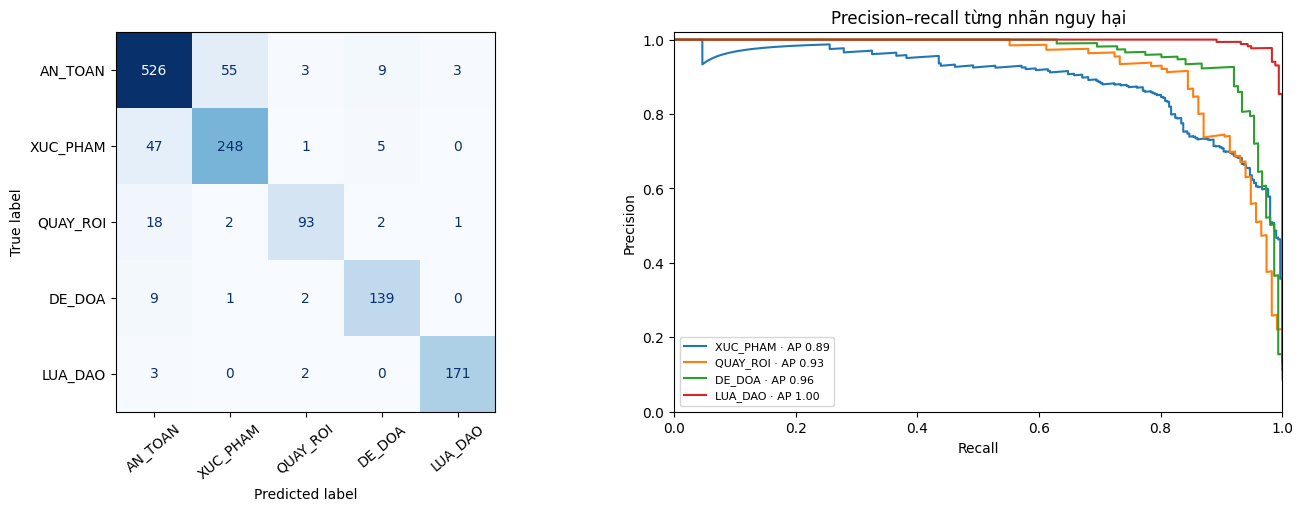

In [ ]:
EVALUATE_AUDIT = False  # Chỉ đặt True MỘT LẦN sau khi đã chốt cấu hình trên dev
def read_human(path):
    gold=[json.loads(line) for line in Path(path).read_text(encoding="utf8").splitlines() if line.strip()]
    training_texts={r["text"].strip().casefold() for r in rows}
    training_ids={r["id"] for r in rows}
    assert gold and len({r["id"] for r in gold})==len(gold)
    for r in gold:
        assert r["id"] not in training_ids and r["text"].strip().casefold() not in training_texts
        assert r["nhan"] in LABELS and all(p and p in r["text"] for p in r["bang_chung"])
        assert r.get("nguon")!="sinh_llm" and r.get("cach_gan")!="llm"
        r["so_dong"]=len(r["text"].split("\n"))
        assert 1<=r["so_dong"]<=8
        r.setdefault("nguon","nguoi")
        r.setdefault("nhom_trung",r["id"])
        r["meta"]={"loai":r["nguon"]}
        assert all("\n" not in p for p in r["bang_chung"])
    return gold

HUMAN_CAL_PATH = None  # file hiệu chuẩn độc lập do người gán, tách khỏi test
human_cal=read_human(HUMAN_CAL_PATH) if HUMAN_CAL_PATH else []
cal=infer(model,[prepare(r) for r in human_cal] if human_cal else encoded["cal"])
cal_source="human" if human_cal else "internal_llm"
if not human_cal:
    print("Ngưỡng nội bộ để thí nghiệm. Hiệu chuẩn lại trên validation người gán trước khi triển khai.")
def arrays(pred):
    return np.array([p["logits"] for p in pred]),np.array([p["gold"] for p in pred])
z,y=arrays(cal)
def nll_temp(log_t):
    return log_loss(y,softmax(z/np.exp(log_t),axis=1),labels=range(len(LABELS)))
cal_fit=minimize_scalar(nll_temp,bounds=(-2.3,2.3),method="bounded")
if not cal_fit.success or not np.isfinite([cal_fit.x,cal_fit.fun]).all():
    raise RuntimeError(f"Hiệu chuẩn nhiệt độ thất bại: {cal_fit.message}")
temp=float(np.exp(cal_fit.x)) if cal_fit.fun<nll_temp(0.) else 1.0
grid=np.linspace(.1,.9,33)
threshold=float(max(grid,key=lambda t:(evidence_stats(cal,t)["f1"],-abs(t-.5)))) if SPAN_WEIGHT else 1.1
write_json(RUN/"calibration.json",dict(temperature=temp,span_threshold=threshold,
    nll_before=float(nll_temp(0.)),nll_after=float(nll_temp(np.log(temp))),
    source=cal_source,ids=[p["id"] for p in cal]))
print("Nhiệt độ, ngưỡng bằng chứng",temp,threshold)

def calibration_stats(prob,y):
    confidence=prob.max(1)
    correct=prob.argmax(1)==y
    ece=0.
    for mask in (np.minimum((confidence*10).astype(int),9)==i for i in range(10)):
        if mask.any(): ece+=mask.mean()*abs(correct[mask].mean()-confidence[mask].mean())
    return dict(nll=float(log_loss(y,prob,labels=range(len(LABELS)))),ece10=float(ece),
                brier=float(((prob-np.eye(len(LABELS))[y])**2).sum(1).mean()))

def format_output(item,text):
    prob=softmax(np.array(item["logits"])/temp)
    label=int(prob.argmax())
    runs=[]
    if label and SPAN_WEIGHT:
        for a,b,score,_ in item["words"]:
            if score<threshold: continue
            if runs and re.fullmatch(r"[^\S\n]*",text[runs[-1][1]:a]):
                runs[-1][1]=b
            else: runs.append([a,b])
    return dict(nhan=LABELS[label],tin_cay=float(prob[label]),bang_chung=[text[a:b] for a,b in runs],
                vi_tri=runs)

def evaluate(pred,records):
    z,y=arrays(pred)
    yp=z.argmax(1)
    result=dict(macro_f1=float(macro(pred)),accuracy=float((y==yp).mean()),
                binary_f1=float(f1_score(y!=0,yp!=0,zero_division=0)),
                classes=classification_report(y,yp,labels=range(5),target_names=LABELS,zero_division=0,output_dict=True),
                confusion=confusion_matrix(y,yp,labels=range(5)).tolist(),
                calibration_before=calibration_stats(softmax(z,axis=1),y),
                calibration_after=calibration_stats(softmax(z/temp,axis=1),y),
                evidence=evidence_stats(pred,threshold),evidence_without_gate=evidence_stats(pred,threshold,False))
    slices=defaultdict(list)
    for i,r in enumerate(records):
        for key in [r["meta"]["loai"],"1 lượt" if r["so_dong"]==1 else "nhiều lượt",*r.get("the",[])]:
            slices[key].append(i)
    result["slices"]={}
    for key,ix in slices.items():
        present=np.unique(y[ix])
        result["slices"][key]=dict(n=len(ix),labels=[LABELS[j] for j in present],
            macro_present=float(f1_score(y[ix],yp[ix],average="macro",labels=present,zero_division=0)),
            accuracy=float((y[ix]==yp[ix]).mean()),evidence=evidence_stats([pred[i] for i in ix],threshold))
    result["recall_nguon_va_nhan"]={}
    for source in sorted({r["meta"]["loai"] for r in records}):
        table={}
        for j,label in enumerate(LABELS):
            ix=[i for i,r in enumerate(records) if r["meta"]["loai"]==source and y[i]==j]
            table[label]={"n":len(ix),"recall":float((yp[ix]==j).mean()) if ix else None}
        result["recall_nguon_va_nhan"][source]=table
    # Mỗi lần chọn lại cả nhóm để không coi các đoạn cùng prompt là độc lập.
    group_names,inverse=np.unique([split_group(r) for r in records],return_inverse=True)
    matrices=np.zeros((len(group_names),len(LABELS),len(LABELS)),dtype=np.int64)
    np.add.at(matrices,(inverse,y,yp),1)
    rng=np.random.default_rng(SEED)
    scores=[]
    for _ in range(500):
        cm=matrices[rng.integers(0,len(matrices),len(matrices))].sum(0)
        scores.append((2*cm.diagonal()/np.maximum(cm.sum(0)+cm.sum(1),1)).mean())
    result["macro_f1_bootstrap_95"]=np.quantile(scores,[.025,.975]).tolist()
    return result

def report_split(key):
    data=encoded[key]
    records=[e["row"] for e in data]
    pred=infer(model,data)
    result=evaluate(pred,records)
    write_json(RUN/f"{key}_metrics.json",result)
    with (RUN/f"{key}_predictions.jsonl").open("w",encoding="utf8") as f:
        for p,r in zip(pred,records):
            record=dict(id=r["id"],nhan_dung=r["nhan"],nguon=r["nguon"],**format_output(p,r["text"]))
            f.write(json.dumps(record,ensure_ascii=False)+"\n")
    print(key, "macro-F1",result["macro_f1"],"95%",result["macro_f1_bootstrap_95"],
          "F1 bằng chứng",result["evidence"]["f1"])
    print(pd.DataFrame(result["confusion"],index=LABELS,columns=LABELS))
    print(pd.DataFrame(result["classes"]).T)
    print(pd.DataFrame(result["slices"]).T[["n","macro_present","accuracy"]])
    return pred
report_key="audit" if EVALUATE_AUDIT else "dev"
final_pred=report_split(report_key)

# Biểu đồ trên cấu hình đã khóa. Trục hàng là nhãn đúng, cột là nhãn dự đoán.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, average_precision_score
fig,axes=plt.subplots(1,2,figsize=(13,5),layout="constrained")
z_eval,y_eval=arrays(final_pred)
ConfusionMatrixDisplay.from_predictions(y_eval,z_eval.argmax(1),labels=range(5),display_labels=LABELS,
                                        xticks_rotation=40,ax=axes[0],colorbar=False,cmap="Blues")
prob_eval=softmax(z_eval/temp,axis=1)
for j,name in enumerate(LABELS[1:],start=1):
    target=(y_eval==j)
    precision,recall,_=precision_recall_curve(target,prob_eval[:,j])
    ap=average_precision_score(target,prob_eval[:,j])
    axes[1].plot(recall,precision,label=f"{name} · AP {ap:.2f}")
axes[1].set(xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02),title="Precision–recall từng nhãn nguy hại")
axes[1].legend(fontsize=8)
fig.savefig(RUN/f"{report_key}_diagnostics.png",dpi=140)
plt.show()

# Chỉ dùng sau khi đã đóng băng mô hình và hoàn tất khử trùng với tập người gán.
GOLD_PATH = None  # đường dẫn JSONL trên Drive, mỗi mẫu có id, text, nhan, bang_chung
if GOLD_PATH:
    gold=read_human(GOLD_PATH)
    assert not ({r["id"] for r in gold} & {r["id"] for r in human_cal})
    assert not ({r["text"].strip().casefold() for r in gold} & {r["text"].strip().casefold() for r in human_cal})
    g=[prepare(r) for r in gold]
    results=evaluate(infer(model,g),gold)
    write_json(RUN/"gold_metrics.json",results)
    print("Tập người gán",len(gold),"macro-F1",results["macro_f1"])

## Độ bền, độ trễ và suy luận
Bộ phân loại cây chỉ dùng độ dài làm mốc so sánh. Trên cùng các mẫu đa lượt, so kết quả khi giữ cả đoạn và khi chỉ đọc lượt cuối. Phép thử ghép cặp dưới đây bỏ dấu tiếng Việt trên cùng các câu và so dự đoán với bản gốc. Báo riêng tập con thật sự thay đổi. Đây là một phép thử độ bền chính tả. Ma trận C1/C2 chính thức và F1 theo ý cần dữ liệu đánh giá tương ứng. Benchmark batch 1 gồm lượt truyền mô hình và chuyển tensor lên thiết bị, với tokenizer được đo riêng. Chờ CUDA hoàn tất trước khi dừng đồng hồ.

In [ ]:
changed=[]
original=[]
for e,p in zip(encoded[report_key],final_pred):
    r=e["row"]
    variant=strip_accents(r["text"])
    if variant!=r["text"]:
        changed.append(prepare(dict(r,text=variant,bang_chung=[])))
        original.append(p)
if changed:
    stress=infer(model,changed)
    a,truth=arrays(original)
    b,_=arrays(stress)
    write_json(RUN/f"{report_key}_accent_stress.json",dict(n=len(stress),original_f1=float(macro(original)),
        stripped_f1=float(macro(stress)),flip_rate=float((a.argmax(1)!=b.argmax(1)).mean()),
        newly_missed_harm=int(((truth!=0)&(a.argmax(1)!=0)&(b.argmax(1)==0)).sum())))
    print((RUN/f"{report_key}_accent_stress.json").read_text())

# Baseline chỉ dùng độ dài. Mô hình này không đọc nội dung hoặc metadata nguồn.
from sklearn.tree import DecisionTreeClassifier
def lengths(e):
    t=e["row"]["text"]
    return [len(t.splitlines()),len(t),len(t.split())]
length_model=DecisionTreeClassifier(max_depth=4,min_samples_leaf=5,class_weight="balanced",random_state=SEED)
length_model.fit([lengths(e) for e in encoded["fit"]],[e["label"] for e in encoded["fit"]])
comparison_data=encoded[report_key]
length_pred=length_model.predict([lengths(e) for e in comparison_data])
diag={"length_only_macro_f1":float(f1_score([e["label"] for e in comparison_data],length_pred,
                                            average="macro",labels=range(5),zero_division=0))}
# So trên đúng các mẫu đa lượt và cùng nhãn đoạn. Đây là phép bỏ ngữ cảnh tại inference.
mult=[(e,p) for e,p in zip(comparison_data,final_pred) if e["row"]["so_dong"]>1]
if mult:
    last_turn=[prepare(dict(e["row"],text=e["row"]["text"].split("\n")[-1],bang_chung=[])) for e,_ in mult]
    truncated_pred=infer(model,last_turn)
    diag.update(multi_n=len(mult),full_context_multi_macro_f1=float(macro([p for _,p in mult])),
                last_turn_multi_macro_f1=float(macro(truncated_pred)))
write_json(RUN/f"{report_key}_context_checks.json",diag)
print(diag)

@torch.inference_mode()
def benchmark(net,data,device,limit=100):
    net.eval()
    samples=data[:limit]
    def sync():
        if device.type=="cuda": torch.cuda.synchronize(device)
    def call(e):
        with (amp() if device.type=="cuda" else nullcontext()):
            return net(to_device(collate([e]),device))
    for e in samples[:5]: call(e)
    sync()
    if device.type=="cuda": torch.cuda.reset_peak_memory_stats(device)
    latency,prep=[],[]
    for e in samples:
        start=time.perf_counter()
        prepare(e["row"])
        prep.append(1000*(time.perf_counter()-start))
        start=time.perf_counter()
        call(e)
        sync()
        latency.append(1000*(time.perf_counter()-start))
    return dict(n=len(samples),batch=1,model_and_collate_p50_ms=float(np.median(latency)),
                model_and_collate_p95_ms=float(np.percentile(latency,95)),
                prepare_p50_ms=float(np.median(prep)),
                session_peak_cuda_MiB=torch.cuda.max_memory_allocated(device)/2**20 if device.type=="cuda" else None)
perf=benchmark(model,encoded[report_key],DEVICE)
write_json(RUN/"benchmark.json",perf)
print(perf)

def predict_text(net,text,device=DEVICE):
    if not text.strip() or not 1<=len(text.split("\n"))<=8:
        raise ValueError("Nhập 1–8 lượt, mỗi lượt một dòng")
    stub=dict(id="demo",text=text,nhan="AN_TOAN",bang_chung=[])
    item=infer(net,[prepare(stub)],device=device)[0]
    return format_output(item,text)
restore(model,load_file(str(RUN/"adapter.safetensors")))
print(predict_text(model,"Chiều nay nhóm mình họp lúc mấy giờ?\nBa giờ ở thư viện nhé."))

{
  "n": 1216,
  "original_f1": 0.890088233883626,
  "stripped_f1": 0.7500575464117651,
  "flip_rate": 0.22861842105263158,
  "newly_missed_harm": 95
}
{'length_only_macro_f1': 0.29712073883379764, 'multi_n': 587, 'full_context_multi_macro_f1': 0.9335009651383789, 'last_turn_multi_macro_f1': 0.6816207204840435}
{'n': 100, 'batch': 1, 'model_and_collate_p50_ms': 71.05028400019364, 'model_and_collate_p95_ms': 109.21557219930946, 'prepare_p50_ms': 0.5145109998920816, 'session_peak_cuda_MiB': 1219.57080078125}
{'nhan': 'AN_TOAN', 'tin_cay': 0.981637972290338, 'bang_chung': [], 'vi_tri': []}


## INT8 trên CPU (tùy chọn)
Bật RUN_INT8_CPU để gộp LoRA vào các phép chiếu trước khi lượng tử hóa động các lớp tuyến tính của backbone. Giữ embedding và các đầu ra ở FP32. So sánh FP32/INT8 trên cùng mẫu và cùng CPU, cùng ngưỡng. Bản này lưu state dict dành cho PyTorch CPU x86. Số byte của tệp và bộ nhớ thực thi là hai phép đo riêng. Trần 2 GB khi chạy trong trình duyệt cần được kiểm tra trên bản xuất và runtime của trình duyệt.

In [ ]:
if RUN_INT8_CPU:
    import copy
    cpu=torch.device("cpu")
    if "x86" in torch.backends.quantized.supported_engines:
        torch.backends.quantized.engine="x86"
    subset=encoded[report_key][:min(256,len(encoded[report_key]))]
    # Kết thúc huấn luyện rồi mới đưa backbone về CPU.
    cpu_net=copy.deepcopy(model.to(cpu)).float().eval()
    model.to(DEVICE)
    cpu_net.backbone.gradient_checkpointing_disable()
    for layer in cpu_net.backbone.layers:
        for name in ("q_proj","k_proj","v_proj","o_proj"):
            adapter=getattr(layer.self_attn,name)
            with torch.no_grad():
                adapter.base.weight.addmm_(adapter.up.weight,adapter.down.weight,alpha=adapter.scale)
            setattr(layer.self_attn,name,adapter.base)
    fp=infer(cpu_net,subset,device=cpu)
    fp_perf=benchmark(cpu_net,subset,cpu)
    from torch.ao.quantization import quantize_dynamic
    quantize_dynamic(cpu_net.backbone,{nn.Linear},dtype=torch.qint8,inplace=True)
    qi=infer(cpu_net,subset,device=cpu)
    tmp=RUN/"int8.tmp"
    torch.save(cpu_net.state_dict(),tmp)
    os.replace(tmp,RUN/"int8_cpu.pt")
    quant_result=dict(n=len(subset),engine=torch.backends.quantized.engine,
        fp32=evaluate(fp,[e["row"] for e in subset]),int8=evaluate(qi,[e["row"] for e in subset]),
        fp32_perf=fp_perf,int8_perf=benchmark(cpu_net,subset,cpu),
        serialized_MiB=(RUN/"int8_cpu.pt").stat().st_size/2**20)
    write_json(RUN/"int8_comparison.json",quant_result)
    print("FP32 / INT8 macro-F1",macro(fp),macro(qi),quant_result["serialized_MiB"],"MiB")

## Đọc kết quả và chọn cấu hình
1. Mặc định chạy smoke để kiểm tra GPU, tải trọng số, Drive và checkpoint; sau đó đổi `RUN_MODE = "full"` để học đầy đủ. Chạy full để có kết quả trên toàn bộ phần fit. Adapter, các đầu ra, cấu hình, danh sách ID, lịch sử, dự đoán, hiệu chuẩn và độ trễ nằm trong thư mục RUN in ở đầu notebook. Khi phiên khác cần suy luận, chạy lại các ô định nghĩa với cùng cấu hình, dựng lại backbone đúng hai revision, nạp adapter và đọc temperature, span_threshold từ calibration.json. Có thể tách ô huấn luyện khỏi phiên suy luận.
2. Với ngân sách **một lượt**, dùng cấu hình mặc định. Nếu so kiến trúc, đánh giá trên dev với cùng seed và cùng split. So tỷ lệ trộn 0 với 0,5, cấu hình flat với hier, rồi loss bằng chứng 0 với 0,35. Flat dùng cùng bộ gộp với một lượt duy nhất, có chia khối với đoạn dài. Mỗi lượt chỉ đổi một yếu tố. Chạy thêm nhiều seed để đo độ ổn định, giữ split cố định khi so hiệu ứng seed tối ưu hóa. Sau khi chốt cấu hình, đặt `EVALUATE_AUDIT = True` và kiểm tra audit đúng một lần. Số liệu học đơn nhãn không đo khả năng tìm đồng thời nhiều hành vi.
3. Kiểm tra confusion, recall từng lớp, F1 bằng chứng, tỷ lệ tô oan, NLL/ECE và các trường hợp dự đoán sai. Nhãn thật/sinh trong báo cáo đề cập **nguồn văn bản**. Toàn bộ mẫu đa lượt và tất cả mẫu lừa đảo của bộ này là văn bản sinh. Bootstrap chỉ phản ánh biến thiên trong phân phối nội bộ. Khi có test do người gán, giữ nguyên checkpoint và ngưỡng rồi đánh giá riêng trên tin nhắn thật.
4. Khi GPU thiếu bộ nhớ, giảm batch vật lý, tăng tích lũy tương ứng và theo dõi thời gian mỗi epoch. Độ trễ GPU Colab, dung lượng state dict INT8 và RAM đỉnh trên thiết bị đích cần báo riêng. Để quyết định triển khai, đo lại F1 nhãn hiếm, bằng chứng và độ trễ p95 sau lượng tử hóa. Chỉ cân nhắc QAT nếu PTQ làm giảm chất lượng có ý nghĩa trên tập độc lập.

## Đối chiếu API và điều kiện kiểm chứng

| Phần | Cách áp dụng trong notebook | Tài liệu chính thức |
|---|---|---|
| Cài đặt và Drive | Kiểm phiên bản đang nạp trong kernel, ghi môi trường ngay khi tạo thư mục run. Dữ liệu và model tải về ổ runtime, checkpoint ghi vào Drive theo epoch. Colab có thể đổi GPU giữa các phiên. | [Colab](https://research.google.com/colaboratory/faq.html) · [Gói Transformers đã ghim](https://pypi.org/project/transformers/4.57.6/) |
| Tải và trộn | Ghim revision, kiểm HTTP và SHA-256 của JSONL. Đọc tensor SafeTensors theo tên, kiểm tra hình dạng và chỉ trộn các hàng embedding có chung token. | [Requests](https://requests.readthedocs.io/en/latest/user/quickstart/#timeouts) · [Hub](https://huggingface.co/docs/huggingface_hub/guides/download) · [SafeTensors](https://huggingface.co/docs/safetensors/api/torch) |
| Chia tập và bằng chứng | StratifiedGroupKFold giữ nguyên nhóm. Kiểm tra offset trên hai lượt với NFC, NFD và bỏ dấu. Khi ghép chunk, offset vẫn thuộc văn bản gốc. | [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) · [Tokenizers](https://huggingface.co/docs/tokenizers/python/latest/quicktour.html) |
| Qwen3 và padding | Dùng đường truyền mặt nạ `full_attention` của phiên bản đã ghim. SDPA nhận True tại vị trí được nhìn. Ô khởi tạo so logits và điểm token khi đặt cùng câu vào batch có thêm padding, đồng thời thử đổi token phía sau. | [Mã Qwen3 v4.57.6](https://github.com/huggingface/transformers/blob/v4.57.6/src/transformers/models/qwen3/modeling_qwen3.py) · [PyTorch SDPA](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html) |
| Huấn luyện | BF16 cần hỗ trợ phần cứng. FP16 dùng GradScaler. Cross-entropy của nhãn và nguyên mẫu cùng dùng mẫu số tổng trọng số lớp. BCE dùng số token có nhãn. Mỗi cửa sổ tích lũy chỉ unscale, clip và step một lần. | [BF16](https://docs.pytorch.org/docs/stable/generated/torch.cuda.is_bf16_supported.html) · [AMP](https://docs.pytorch.org/docs/stable/notes/amp_examples.html) · [CE](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) · [BCE](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) |
| Lưu và tiếp tục | Activation checkpointing dùng `use_reentrant=False`. Tệp `last.pt` giữ trọng số đang học, bản tốt nhất và trạng thái AdamW, lịch LR, scaler. Mỗi epoch có seed được xác định từ chỉ số epoch. Khôi phục bằng cùng cấu hình và dtype. Bản sửa loss dùng thư mục run mới. | [Activation checkpoint](https://docs.pytorch.org/docs/stable/checkpoint.html) · [Lưu, nạp checkpoint](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) · [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html) |
| Hiệu chuẩn và báo cáo | Kiểm tra hội tụ của SciPy trước khi lưu nhiệt độ. Chọn ngưỡng trên cal, tính macro-F1 và báo khoảng bootstrap nhóm trên tập báo cáo. Bảng tần suất và biểu đồ dùng pandas và Matplotlib. | [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html) · [F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) · [NumPy](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html) · [pandas](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html) · [Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html) |
| Benchmark | Đồng bộ CUDA trước khi đọc thời gian. Số đo VRAM là đỉnh tensor được PyTorch cấp trong phiên benchmark. INT8 động là thử nghiệm CPU tùy chọn qua API eager, kết quả phụ thuộc engine và bản PyTorch. | [CUDA memory](https://docs.pytorch.org/docs/stable/generated/torch.cuda.max_memory_allocated.html) · [Lộ trình lượng tử hóa](https://docs.pytorch.org/docs/stable/quantization.html) |

Để xác nhận môi trường Colab thực tế, chạy smoke trên GPU, kiểm tra `environment.json`, sau đó mở một phiên mới có cùng dtype và chạy lại cùng cấu hình. Ô huấn luyện sẽ khôi phục epoch đã lưu. Drive và RAM/VRAM trên thiết bị đích cần kiểm chứng trực tiếp.

## Ghi chú kiểm tra tương thích
Notebook này được kiểm tra về cấu trúc và cú pháp. Các bản phát hành được ghim, file mô hình và đường attention trong Transformers 4.57.6 được đối chiếu với tài liệu. Việc huấn luyện thực tế, xác thực checksum dữ liệu và đo VRAM cần thực hiện trong phiên Colab có GPU. Ô khởi tạo mô hình trong phần trên kiểm thử attention hai chiều và tính bất biến với padding. Bản kiểm tra này **không** thay thế smoke run trên GPU.

### Bản sửa lỗi thực thi FP16 trên Tesla T4 (theo log Colab)

Đã ép biểu diễn chiếu `h` về FP32 ngay sau `self.project(...)` trước các phép gom lượt `index_add`, đồng thời áp dụng cho đường gom bằng chứng `cue` sử dụng `h.new_zeros`. Đây là phần gom nhỏ theo chiều `WIDTH`; backbone và LoRA vẫn dùng AMP/FP16 như cấu hình. Sửa lỗi `RuntimeError: index_add_(): self (Half) and source (Float) must have the same scalar type` xuất hiện ở cell khởi tạo mô hình. Sau khi thay notebook, khởi động lại session để giải phóng mô hình GPU cũ, sau đó chạy lại với `RUN_MODE = "smoke"`.
